# PCE Model for Depth-Based CPT Prediction (Multi-Output)


In [303]:
from __future__ import annotations

import importlib
import os
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from sklearn.model_selection import train_test_split
from uqpylab import sessions

# Import utility functions from modules
from data_loading import PCE_database_total
from pce_utils import calculate_r2
import utils 
import re
import pandas as pd

from config import UQCLOUD_TOKEN
myToken = UQCLOUD_TOKEN

# Reload utils module to pick up any changes
importlib.reload(utils)
from utils import (
    nrmsd,
    set_graphics_defaults,
)

# Notebook-compatible path resolution
if Path.cwd().name == "src":
    ROOT = Path.cwd().parent
else:
    ROOT = Path.cwd()

DATA_DIR = ROOT / "data"
PLOTS_DIR = ROOT / "graphics"
PLOTS_DIR.mkdir(exist_ok=True)
cm = 1/2.54


In [304]:
# Start UQ[PY]LAB session
UQCloud_instance = os.environ.get("UQCLOUD_HOST", "https://uqcloud.ethz.ch")
myToken = os.environ.get("UQCLOUD_TOKEN", f"{myToken}")

mySession = sessions.cloud(host=UQCloud_instance, token=myToken, strict_ssl=True)
uq = mySession.cli
mySession.reset()

print("UQ[PY]LAB session started.")

Processing . done!

 uqpylab.sessions :: INFO     :: Reset successful.
UQ[PY]LAB session started.


In [305]:
input_sheet = ["verysoft", "soft", "medium", "stiff", "map"]
input_sheet = input_sheet[4]  # Select the sheet for processing

ed, out, var_names, param_ranges = PCE_database_total(sheet_name=input_sheet, cr_cscc=True)

Loaded 200 rows from 'map' in GPFEM_database_20260624.xlsx, dropped 0 rows with NaN values, 200 rows remaining.


In [306]:
# out_matrix = np.column_stack([out["qt"], out["fs"], out["u2"]])

# Use log(fs) as second output
fs_log = np.log(out["fs"])
out_matrix = np.column_stack([out["qt"], fs_log, out["u2"]])

print(f"Loaded {ed.shape[0]} samples with {ed.shape[1]} input parameters and {out_matrix.shape} output parameters")

Loaded 200 samples with 6 input parameters and (200, 3) output parameters


In [307]:
print(f"\nParameter ranges from data:")
for param_name, (p_min, p_max) in param_ranges.items():
    print(f"  {param_name}: [{p_min:.6f}, {p_max:.6f}]")


Parameter ranges from data:
  z: [5.049355, 19.953525]
  unit_weight: [14.516493, 18.993165]
  friction_angle: [15.005246, 34.971546]
  ocr: [1.004419, 3.993565]
  cr: [0.070397, 0.398877]
  cs_cc: [0.100702, 0.333226]


In [308]:
print("\nOutput ranges from data:")
for name, arr in out.items():
    arr = np.asarray(arr, dtype=float)
    print(f"  {name}: [{arr.min():.6f}, {arr.max():.6f}]")


Output ranges from data:
  qt: [172.049193, 1889.959024]
  fs: [3.369528, 57.092222]
  u2: [99.429551, 726.794087]


In [309]:
latex_names = {
    "z": "z (m)",
    "unit_weight": r"$\gamma_{\mathrm{sat}}$ (kN/m$^3$)",
    "friction_angle": r"$\varphi'~(°)$",
    "orc": "OCR (-)",
    "cr": r"$\mathrm{CR}$ (-)",
    "cs_cc": r"$C_{\mathrm{s}}/C_{\mathrm{c}}$ (-)",
}

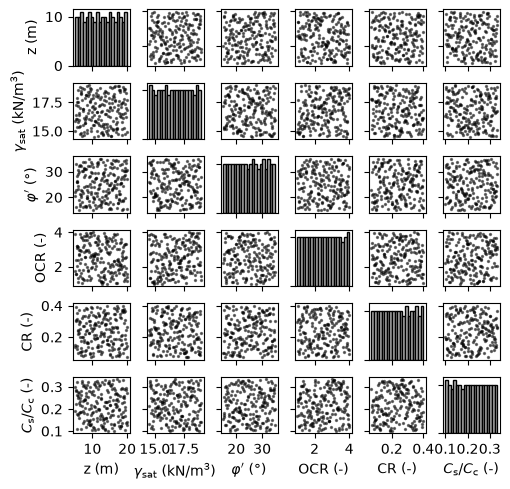

In [310]:
# Select 8 variables: 6 inputs + 2 outputs (example: qt, fs)
plot_vars = [
    ("z [m]",        "z",            ed[:, var_names.index("z [m]")]),
    ("γ [kN/m3]",    "unit_weight",  ed[:, var_names.index("γ [kN/m3]")]),
    ("φ' [deg]",     "friction_angle", ed[:, var_names.index("φ' [deg]")]),
    ("OCR",          "orc",          ed[:, var_names.index("OCR")]),
    ("CR",           "cr",           ed[:, var_names.index("CR")]),
    ("cs/cc",        "cs_cc",        ed[:, var_names.index("cs/cc")]),
    # ("$q_t$ (kPa)",           "qt",           out["qt"]),
    # ("$f_s$ (kPa)",           "fs",           out["fs"]),
    # ("$u_2$ (kPa)",           "u2",           out["u2"]),
]

n = len(plot_vars)

def label_from_key(key, fallback):
    return latex_names.get(key, fallback)

fig, axes = plt.subplots(
    n, n,
    figsize=(14 * cm, 14 * cm),  # width fixed, square grid
    sharex=False,
    sharey=False,
)

axes = np.atleast_2d(axes)

for i in range(n):          # rows: y-variable
    for j in range(n):      # cols: x-variable
        ax = axes[i, j]
        name_i, key_i, data_i = plot_vars[i]
        name_j, key_j, data_j = plot_vars[j]

        if i == j:
            # Diagonal: distribution of variable i
            ax.hist(data_i, bins=20, color="0.7", edgecolor="k")
        else:
            # Off-diagonal: scatter of (x=j, y=i)
            ax.scatter(data_j, data_i, c = 'k' , s=2, alpha=0.5)

        # Axis labels only on left column / bottom row
        if j == 0:
            ax.set_ylabel(label_from_key(key_i, name_i))
        else:
            ax.set_yticklabels([])

        if i == n - 1:
            ax.set_xlabel(label_from_key(key_j, name_j))
        else:
            ax.set_xticklabels([])
plt.subplots_adjust(wspace = 0.3, hspace = 0.3)

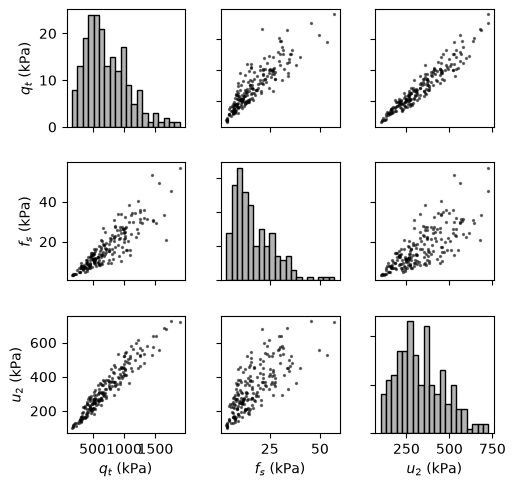

In [311]:
# Select 8 variables: 6 inputs + 2 outputs (example: qt, fs)
plot_vars = [
    # ("z [m]",        "z",            ed[:, var_names.index("z [m]")]),
    # ("γ [kN/m3]",    "unit_weight",  ed[:, var_names.index("γ [kN/m3]")]),
    # ("φ' [deg]",     "friction_angle", ed[:, var_names.index("φ' [deg]")]),
    # ("OCR",          "orc",          ed[:, var_names.index("OCR")]),
    # ("CR",           "cr",           ed[:, var_names.index("CR")]),
    # ("cs/cc",        "cs_cc",        ed[:, var_names.index("cs/cc")]),
    ("$q_t$ (kPa)",           "qt",           out["qt"]),
    ("$f_s$ (kPa)",           "fs",           out["fs"]),
    ("$u_2$ (kPa)",           "u2",           out["u2"]),
]

n = len(plot_vars)

def label_from_key(key, fallback):
    return latex_names.get(key, fallback)

fig, axes = plt.subplots(
    n, n,
    figsize=(14 * cm, 14 * cm),  # width fixed, square grid
    sharex=False,
    sharey=False,
)

axes = np.atleast_2d(axes)

for i in range(n):          # rows: y-variable
    for j in range(n):      # cols: x-variable
        ax = axes[i, j]
        name_i, key_i, data_i = plot_vars[i]
        name_j, key_j, data_j = plot_vars[j]

        if i == j:
            # Diagonal: distribution of variable i
            ax.hist(data_i, bins=20, color="0.7", edgecolor="k")
        else:
            # Off-diagonal: scatter of (x=j, y=i)
            ax.scatter(data_j, data_i, c = 'k' , s=2, alpha=0.5)

        # Axis labels only on left column / bottom row
        if j == 0:
            ax.set_ylabel(label_from_key(key_i, name_i))
        else:
            ax.set_yticklabels([])

        if i == n - 1:
            ax.set_xlabel(label_from_key(key_j, name_j))
        else:
            ax.set_xticklabels([])
plt.subplots_adjust(wspace = 0.3, hspace = 0.3)

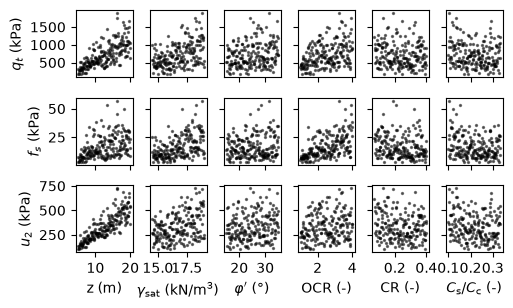

In [312]:
cm = 1 / 2.54

# Inputs (same style as before: name, key, data)
input_vars = [
    ("z [m]",        "z",            ed[:, var_names.index("z [m]")]),
    ("γ [kN/m3]",    "unit_weight",  ed[:, var_names.index("γ [kN/m3]")]),
    ("φ' [deg]",     "friction_angle", ed[:, var_names.index("φ' [deg]")]),
    ("OCR",          "orc",          ed[:, var_names.index("OCR")]),
    ("CR",           "cr",           ed[:, var_names.index("CR")]),
    ("cs/cc",        "cs_cc",        ed[:, var_names.index("cs/cc")]),
]

# Outputs: label, key, data
output_vars = [
    ("$q_t$ (kPa)",  "qt", out["qt"]),
    ("$f_s$ (kPa)",  "fs", out["fs"]),
    ("$u_2$ (kPa)",  "u2", out["u2"]),
]

n_in = len(input_vars)
n_out = len(output_vars)

def label_from_key(key, fallback):
    return latex_names.get(key, fallback)

fig, axes = plt.subplots(
    n_out, n_in,
    figsize=(14 * cm, 8 * cm),  # fixed width, height scales with outputs
    sharex=False,
    sharey=False,
)

axes = np.atleast_2d(axes)

for i in range(n_out):      # rows = outputs (y-axis)
    for j in range(n_in):   # cols = inputs (x-axis)
        ax = axes[i, j]
        out_label, out_key, y = output_vars[i]
        in_label, in_key, x = input_vars[j]

        ax.scatter(x, y, c="k", s=2, alpha=0.5)

        # y-labels only on first column
        if j == 0:
            ax.set_ylabel(out_label)
        else:
            ax.set_yticklabels([])

        # x-labels only on bottom row
        if i == n_out - 1:
            ax.set_xlabel(label_from_key(in_key, in_label))
        else:
            ax.set_xticklabels([])

plt.subplots_adjust(wspace=0.3, hspace=0.3)

In [313]:
# Build marginals for the 6 inputs we actually have: z, γ, φ', OCR, CR, cs/cc
marginals_list = []

# Map var_names to keys in param_ranges
key_map = {
    "z [m]":        "z",
    "γ [kN/m3]":    "unit_weight",
    "φ' [deg]":     "friction_angle",
    "OCR":          "ocr",
    "CR":           "cr",
    "cs/cc":        "cs_cc",
}

for name in var_names:
    key = key_map.get(name)
    if key is None or key not in param_ranges:
        raise KeyError(f"No range found for variable {name} (key '{key}')")
    p_min, p_max = param_ranges[key]
    marginals_list.append({
        "Name": name,
        "Type": "Uniform",
        "Parameters": [p_min, p_max],
    })

# Create UQPyLab input
my_input = uq.createInput({"Marginals": marginals_list})

print(f"\nInput structure created with {len(my_input['Marginals'])} parameters (in order):")
for i, marginal in enumerate(my_input["Marginals"]):
    print(f"  {i+1}. {marginal['Name']}")

# Inference data: X from ed, Y from qt/fs/u2
X_inference = ed

fs_log = np.log(out["fs"])
# output_matrix = np.column_stack([out["qt"], out["fs"], out["u2"]])
output_matrix = np.column_stack([out["qt"], fs_log, out["u2"]])
output_var_names = ["qt", "fs", "u2"]

X_train, X_test, Y_train, Y_test = train_test_split(
    X_inference, output_matrix, test_size=0.2, random_state=33
)

print(f"\nTrain/test split (80/20): X_train {X_train.shape}, X_test {X_test.shape}")


Input structure created with 6 parameters (in order):
  1. z [m]
  2. γ [kN/m3]
  3. φ' [deg]
  4. OCR
  5. CR
  6. cs/cc

Train/test split (80/20): X_train (160, 6), X_test (40, 6)


In [314]:
# Build multi-output PCE model
print("Building multi-output PCE model...")
print("=" * 60)

# Define configurations to test
configurations = [
    ("LARS", 5, 1e-3),
    ("LARS", 4, 1e-3),
    ("LARS", 6, 1e-3),
    ("LARS", 5, 1e-4),
    ("LARS", 3, 1e-4)
]

best_model = None
best_prediction = None
best_r2 = float('-inf')
best_config = None

print("\nTesting configurations:")
for method, max_degree, target_acc in configurations:
    try:
        meta_opts = {
            "Type": "Metamodel",
            "Input": my_input["Name"],
            "MetaType": "PCE",
            "Degree": list(range(1, max_degree + 1)),
            "Method": method,
            # "TargetAccuracy": target_acc, #not recommended, keep it
            "Display": "quiet",
            "ExpDesign": {
                "X": X_train.tolist(),
                "Y": Y_train.tolist()  # Multi-output: (n_train, 4) depth, qt, fs, u2
            }
        }
        
        my_pce = uq.createModel(meta_opts)
        prediction_test = uq.evalModel(my_pce, X_test.tolist())
        
        # Calculate average R² on test set
        r2_values = []
        for out_idx, out_name in enumerate(output_var_names):
            actual = Y_test[:, out_idx]
            predicted = prediction_test[:, out_idx].flatten()
            r2 = calculate_r2(actual, predicted)
            r2_values.append(r2)
        
        avg_r2 = np.mean(r2_values)
        
        config_str = f"Method={method}, MaxDegree={max_degree}, TargetAcc={target_acc}"
        r2_str = ", ".join([f"{n}={v:.6f}" for n, v in zip(output_var_names, r2_values)])
        print(f"  {config_str}: Avg R² = {avg_r2:.6f} ({r2_str})")
        
        if avg_r2 > best_r2:
            best_r2 = avg_r2
            best_model = my_pce
            best_prediction = prediction_test
            best_config = config_str
            
    except Exception as e:
        print(f"  Method={method}, MaxDegree={max_degree}, TargetAcc={target_acc}: Failed - {str(e)}")
        continue

if best_model is None:
    # Fallback with default settings
    print("  All configurations failed. Trying default configuration as fallback...")
    try:
        meta_opts = {
            "Type": "Metamodel",
            "Input": my_input["Name"],
            "MetaType": "PCE",
            "Degree": list(range(1, 6)),
            "Method": "LARS",
            "Display": "standard",
            "ExpDesign": {
                "X": X_train.tolist(),
                "Y": Y_train.tolist()
            }
        }
        best_model = uq.createModel(meta_opts)
        best_prediction = uq.evalModel(best_model, X_test.tolist())
        
        r2_values = []
        for out_idx, out_name in enumerate(output_var_names):
            actual = Y_test[:, out_idx]
            predicted = best_prediction[:, out_idx].flatten()
            r2 = calculate_r2(actual, predicted)
            r2_values.append(r2)
        best_r2 = np.mean(r2_values)
        best_config = "Fallback: Method=LARS, MaxDegree=5"
        print(f"  Fallback succeeded: Avg R² = {best_r2:.6f}")
    except Exception as e:
        raise RuntimeError(f"Failed to build multi-output PCE model. Error: {str(e)}") from e

print(f"\n→ Selected: {best_config} (Avg R² = {best_r2:.6f})")
print("=" * 60)
print("Multi-output PCE model computed successfully.")

# Extract predictions for each output (depth, qt, u2, fs)
prediction_pce = {
    name: best_prediction[:, idx].flatten()
    for idx, name in enumerate(output_var_names)
}
pce_model = best_model

Building multi-output PCE model...

Testing configurations:
  Method=LARS, MaxDegree=5, TargetAcc=0.001: Avg R² = 0.952739 (qt=0.999144, fs=0.904624, u2=0.954448)
  Method=LARS, MaxDegree=4, TargetAcc=0.001: Avg R² = 0.952739 (qt=0.999144, fs=0.904624, u2=0.954448)
  Method=LARS, MaxDegree=6, TargetAcc=0.001: Avg R² = 0.952739 (qt=0.999144, fs=0.904624, u2=0.954448)
  Method=LARS, MaxDegree=5, TargetAcc=0.0001: Avg R² = 0.952739 (qt=0.999144, fs=0.904624, u2=0.954448)
  Method=LARS, MaxDegree=3, TargetAcc=0.0001: Avg R² = 0.952365 (qt=0.999144, fs=0.904624, u2=0.953327)

→ Selected: Method=LARS, MaxDegree=5, TargetAcc=0.001 (Avg R² = 0.952739)
Multi-output PCE model computed successfully.


In [315]:
# Model Evaluation (on test set)
print("\n" + "=" * 60)
print("MODEL EVALUATION METRICS (Test Set)")
print("=" * 60)

out_test = {name: Y_test[:, idx] for idx, name in enumerate(output_var_names)}
evaluation_results = {}

for out_idx, out_name in enumerate(output_var_names):
    actual = out_test[out_name]
    predicted = prediction_pce[out_name]
    
    # Calculate metrics
    r2 = calculate_r2(actual, predicted)
    rmse = np.sqrt(np.mean((actual - predicted) ** 2))
    mae = np.mean(np.abs(actual - predicted))
    nrmse_range = nrmsd(actual, predicted, norm="range")
    nrmse_std = nrmsd(actual, predicted, norm="std")
    
    # For multi-output PCE, LOO error extraction
    # Note: For multi-output PCE, UQPyLab typically computes LOO error for the first output only
    # We'll try to extract it from the model structure or compute it manually
    loo_rmse = np.nan
    loo_mse = np.nan
    
    # Try to get LOO error from model structure
    try:
        # Check PCE structure directly
        if "PCE" in pce_model:
            pce = pce_model["PCE"]
        else:
            pce = pce_model
        
        # Check for Error structure in PCE
        if "Error" in pce:
            error_obj = pce["Error"]
            if isinstance(error_obj, dict):
                # Check for LOO error (MSE format)
                if "LOO" in error_obj:
                    loo_val = error_obj["LOO"]
                    # For multi-output, LOO might be a list/array per output
                    if isinstance(loo_val, (list, np.ndarray)):
                        loo_array = np.asarray(loo_val).flatten()
                        if len(loo_array) > out_idx:
                            loo_mse = float(loo_array[out_idx])
                            loo_rmse = np.sqrt(loo_mse) if loo_mse > 0 else np.nan
                        elif len(loo_array) == 1 and out_idx == 0:
                            # Single value for first output (common in multi-output)
                            loo_mse = float(loo_array[0])
                            loo_rmse = np.sqrt(loo_mse) if loo_mse > 0 else np.nan
                    elif isinstance(loo_val, (int, float)):
                        # Single scalar value (typically for first output in multi-output)
                        if out_idx == 0:
                            loo_mse = float(loo_val)
                            loo_rmse = np.sqrt(loo_mse) if loo_mse > 0 else np.nan
        
        # Also check top-level Error in model
        if "Error" in pce_model and np.isnan(loo_rmse):
            error_obj = pce_model["Error"]
            if isinstance(error_obj, dict):
                if "LOO" in error_obj:
                    loo_val = error_obj["LOO"]
                    if isinstance(loo_val, (list, np.ndarray)):
                        loo_array = np.asarray(loo_val).flatten()
                        if len(loo_array) > out_idx:
                            loo_mse = float(loo_array[out_idx])
                            loo_rmse = np.sqrt(loo_mse) if loo_mse > 0 else np.nan
                        elif len(loo_array) == 1 and out_idx == 0:
                            loo_mse = float(loo_array[0])
                            loo_rmse = np.sqrt(loo_mse) if loo_mse > 0 else np.nan
                    elif isinstance(loo_val, (int, float)) and out_idx == 0:
                        loo_mse = float(loo_val)
                        loo_rmse = np.sqrt(loo_mse) if loo_mse > 0 else np.nan
        
        # For multi-output models, if LOO is not found per output, 
        # compute it manually using hat matrix approximation
        if np.isnan(loo_rmse):
            try:
                # Manual LOO computation using hat matrix approximation
                n_samples = len(actual)
                residuals = actual - predicted
                
                # Get number of coefficients from PCE model
                if "PCE" in pce_model:
                    pce = pce_model["PCE"]
                else:
                    pce = pce_model
                
                # Estimate number of coefficients
                if "Basis" in pce and "Indices" in pce["Basis"]:
                    n_coeffs = len(pce["Basis"]["Indices"])
                elif "Coefficients" in pce:
                    n_coeffs = len(pce["Coefficients"])
                else:
                    n_coeffs = min(50, n_samples // 2)  # Conservative estimate
                
                # Hat matrix approximation: h_ii ≈ n_coeffs / n_samples
                avg_leverage = n_coeffs / n_samples
                loo_residuals = residuals / (1 - avg_leverage)
                loo_mse = np.mean(loo_residuals ** 2)
                loo_rmse = np.sqrt(loo_mse)
            except:
                pass
                
    except Exception as e:
        # If all extraction methods fail, try manual computation
        try:
            n_samples = len(actual)
            residuals = actual - predicted
            # Simple approximation
            n_coeffs = min(50, n_samples // 2)
            avg_leverage = n_coeffs / n_samples
            loo_residuals = residuals / (1 - avg_leverage)
            loo_mse = np.mean(loo_residuals ** 2)
            loo_rmse = np.sqrt(loo_mse)
        except:
            pass
    
    evaluation_results[out_name] = {
        "R²": r2,
        "RMSE": rmse,
        "MAE": mae,
        "NRMSE (range)": nrmse_range,
        "NRMSE (std)": nrmse_std,
        "LOO RMSE": loo_rmse,
        "LOO MSE": loo_mse,
    }
    
    print(f"\n{out_name.upper()}:")
    print(f"  R² (Coefficient of Determination): {r2:.6f}")
    print(f"  RMSE (Root Mean Squared Error):    {rmse:.4f} {out_name} units")
    print(f"  MAE (Mean Absolute Error):         {mae:.4f} {out_name} units")
    print(f"  NRMSE (Normalized by Range):       {nrmse_range:.6f}")
    print(f"  NRMSE (Normalized by Std):         {nrmse_std:.6f}")
    if not np.isnan(loo_rmse):
        print(f"  LOO RMSE (Leave-One-Out):         {loo_rmse:.6e}")
    else:
        print(f"  LOO RMSE (Leave-One-Out):         Not available")

# Print PCE model details (single multi-output model)
print(f"\nMulti-Output PCE Model Details:")
uq.print(pce_model)



MODEL EVALUATION METRICS (Test Set)

QT:
  R² (Coefficient of Determination): 0.999144
  RMSE (Root Mean Squared Error):    9.7020 qt units
  MAE (Mean Absolute Error):         7.8625 qt units
  NRMSE (Normalized by Range):       0.006193
  NRMSE (Normalized by Std):         0.028883
  LOO RMSE (Leave-One-Out):         1.940401e+01

FS:
  R² (Coefficient of Determination): 0.904624
  RMSE (Root Mean Squared Error):    0.1849 fs units
  MAE (Mean Absolute Error):         0.1260 fs units
  NRMSE (Normalized by Range):       0.072196
  NRMSE (Normalized by Std):         0.304945
  LOO RMSE (Leave-One-Out):         3.698515e-01

U2:
  R² (Coefficient of Determination): 0.954448
  RMSE (Root Mean Squared Error):    28.1831 u2 units
  MAE (Mean Absolute Error):         19.4514 u2 units
  NRMSE (Normalized by Range):       0.045635
  NRMSE (Normalized by Std):         0.210745
  LOO RMSE (Leave-One-Out):         5.636619e+01

Multi-Output PCE Model Details:
printed 
> In <a href="matlab:matl

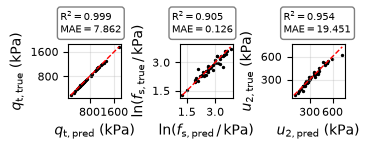

In [316]:
from matplotlib.ticker import MaxNLocator

# plt.rcParams['pdf.fonttype'] = 42

n_out = len(output_var_names)

fig, axes = plt.subplots(1, n_out, figsize=(9*cm, 3.5*cm))
if n_out == 1:
    axes = [axes]

output_labels = {
    "depth": "depth (m)",
    "qt": "$q_t$ (kPa)",
    "fs": "$f_s$ (kPa)",
    "u2": "$u_2$ (kPa)",
}

output_labels1 = {
    "depth": "depth (m)",
    "qt": r"$q_{\mathrm{t, pred}}$ (kPa)",
    "fs": r"$f_{\mathrm{s, pred}}$ (kPa)",
    "u2": r"$u_{\mathrm{2, pred}}$ (kPa)",
}

output_labels2 = {
    "depth": "depth (m)",
    "qt": r"$q_{\mathrm{t, true}}$ (kPa)",
    "fs": r"$f_{\mathrm{s, true}}$ (kPa)",
    "u2": r"$u_{\mathrm{2, true}}$ (kPa)",
}

output_labels_pred = {
    "qt": r"$q_{\mathrm{t,pred}}$ (kPa)",
    "fs": r"$\ln(f_{\mathrm{s,pred}}\,/\,\mathrm{kPa})$",
    "u2": r"$u_{\mathrm{2,pred}}$ (kPa)",
}
output_labels_true = {
    "qt": r"$q_{\mathrm{t,true}}$ (kPa)",
    "fs": r"$\ln(f_{\mathrm{s,true}}\,/\,\mathrm{kPa})$",
    "u2": r"$u_{\mathrm{2,true}}$ (kPa)",
}

for idx, out_name in enumerate(output_var_names):
    ax = axes[idx]
    actual = out_test[out_name]
    predicted = prediction_pce[out_name]

    # Calculate R²
    ss_res = np.sum((actual - predicted) ** 2)
    ss_tot = np.sum((actual - np.mean(actual)) ** 2)
    r2 = 1 - (ss_res / ss_tot) if ss_tot > 1e-12 else 0.0

    # MAE instead of RMSE
    mae = np.mean(np.abs(actual - predicted))

    # Scatter plot
    ax.scatter(actual, predicted, s=2, color='k', rasterized=True)

    # 1:1 line (perfect prediction)
    min_val = min(np.min(actual), np.min(predicted))
    max_val = max(np.max(actual), np.max(predicted))
    ax.plot([min_val, max_val], [min_val, max_val], 'r--', lw=1, label='1:1 line')

    # --- Error Text Box ---
    stats_text = f"$\\mathrm{{R}}^\\mathrm{{2}} = {r2:.3f}$\n$\\mathrm{{MAE}} = {mae:.3f}$"
    ax.text(-0.15, 1.65, stats_text, transform=ax.transAxes,
            verticalalignment='top', horizontalalignment='left',
            fontsize=7, bbox=dict(boxstyle='round', facecolor='white', alpha=0.5))
    # -----------------------------

    # Labels
    lbl1 = output_labels_pred.get(out_name, out_name)
    lbl2 = output_labels_true.get(out_name, out_name)
    ax.set_xlabel(f'{lbl1}')
    ax.set_ylabel(f'{lbl2}')
    ax.grid(True, alpha=0.3)

    # Make axes equal for better visualization
    ax.set_aspect('equal', adjustable='box')

    # Force exactly 3 ticks
    ax.xaxis.set_major_locator(MaxNLocator(nbins=2))
    ax.yaxis.set_major_locator(MaxNLocator(nbins=2))

    ax.tick_params(axis='both', labelsize=8)

    plt.subplots_adjust(left=0.17, bottom=0.08, right=0.95, top=0.98, wspace=1.1, hspace=0.0)
    
    # Save all three formats from the same figure
    base = PLOTS_DIR / "actual_vs_predicted_pce_depth_based"

    plt.savefig(f"{base}.pdf", dpi=1000)
    plt.savefig(f"{base}.tiff", dpi=1000)
    plt.savefig(f"{base}.jpg", dpi=1000)


In [317]:
metrics_df = pd.DataFrame(evaluation_results).T
print("\n" + "=" * 60)
print("SUMMARY OF EVALUATION METRICS")
print("=" * 60)
print(metrics_df.to_string())



SUMMARY OF EVALUATION METRICS
          R²       RMSE        MAE  NRMSE (range)  NRMSE (std)   LOO RMSE      LOO MSE
qt  0.999144   9.702005   7.862450       0.006193     0.028883  19.404011   376.515634
fs  0.904624   0.184926   0.126029       0.072196     0.304945   0.369852     0.136790
u2  0.954448  28.183097  19.451447       0.045635     0.210745  56.366194  3177.147835


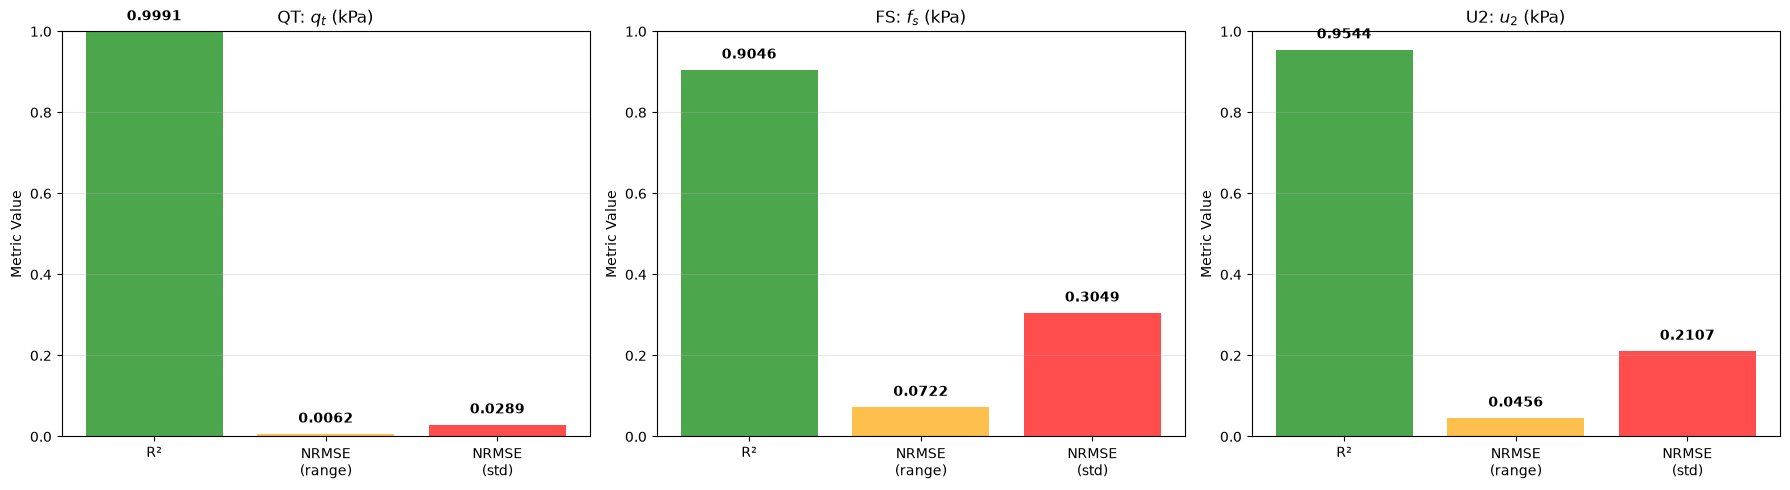

In [318]:
# Plot error metrics comparison
n_out = len(output_var_names)
fig, axes = plt.subplots(1, n_out, figsize=(6 * n_out, 5))
if n_out == 1:
    axes = [axes]
outputs = output_var_names
output_labels = {
    "depth": "depth (m)",
    "qt": "$q_t$ (kPa)",
    "u2": "$u_2$ (kPa)",
    "fs": "$f_s$ (kPa)",
}
output_labels = [output_labels.get(o, o) for o in outputs]

for idx, (out_name, out_label) in enumerate(zip(outputs, output_labels)):
    ax = axes[idx]
    
    metrics = evaluation_results[out_name]
    
    # Create bar plot of key metrics
    metric_names = ["R²", "NRMSE\n(range)", "NRMSE\n(std)"]
    metric_values = [
        metrics["R²"],
        metrics["NRMSE (range)"],
        metrics["NRMSE (std)"],
    ]
    
    bars = ax.bar(metric_names, metric_values, alpha=0.7, color=['green', 'orange', 'red'])
    ax.set_ylabel("Metric Value")
    ax.set_title(f"{out_name.upper()}: {out_label}")
    ax.set_ylim(0, 1.0)
    ax.grid(True, alpha=0.3, axis="y")
    
    # Add value labels on bars
    for bar, val in zip(bars, metric_values):
        height = bar.get_height()
        ax.text(bar.get_x() + bar.get_width()/2., height + 0.02,
                f'{val:.4f}', ha='center', va='bottom', fontweight='bold')

plt.tight_layout()
# plt.savefig(PLOTS_DIR / "pce_depth_based_error_metrics.png", dpi=150, bbox_inches="tight")
plt.show()


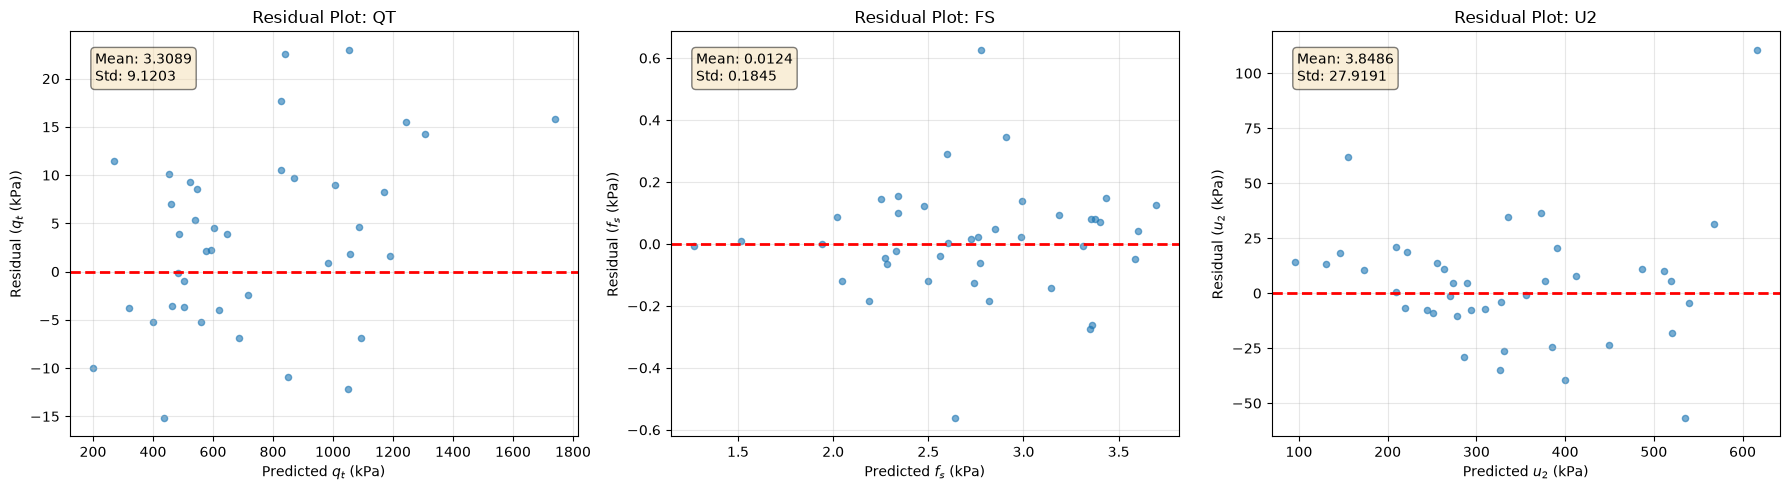

In [319]:
# Plot residuals (prediction errors)
n_out = len(output_var_names)
fig, axes = plt.subplots(1, n_out, figsize=(6 * n_out, 5))
if n_out == 1:
    axes = [axes]
outputs = output_var_names
residual_labels = {"depth": "depth (m)", "qt": "$q_t$ (kPa)", "u2": "$u_2$ (kPa)", "fs": "$f_s$ (kPa)"}
output_labels = [residual_labels.get(o, o) for o in outputs]

for idx, (out_name, out_label) in enumerate(zip(outputs, output_labels)):
    ax = axes[idx]
    
    actual = out_test[out_name]
    predicted = prediction_pce[out_name]
    residuals = actual - predicted
    
    ax.scatter(predicted, residuals, alpha=0.6, s=20)
    ax.axhline(y=0, color='r', linestyle='--', linewidth=2)
    ax.set_xlabel(f"Predicted {out_label}")
    ax.set_ylabel(f"Residual ({out_label})")
    ax.set_title(f"Residual Plot: {out_name.upper()}")
    ax.grid(True, alpha=0.3)
    
    # Add statistics text
    mean_residual = np.mean(residuals)
    std_residual = np.std(residuals)
    ax.text(0.05, 0.95, f"Mean: {mean_residual:.4f}\nStd: {std_residual:.4f}",
            transform=ax.transAxes, verticalalignment='top',
            bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.5))

plt.tight_layout()
# plt.savefig(PLOTS_DIR / "pce_depth_based_residuals.png", dpi=150, bbox_inches="tight")
plt.show()


In [320]:
meta_opts = {
    "Type": "Metamodel",
    "Input": my_input["Name"],
    "MetaType": "PCE",
    "Degree": list(range(1, 4)),
    "Method": method,
    "Display": "quiet",
    "ExpDesign": {
        "X": ed.tolist(),
        "Y": output_matrix.tolist()  
    }
}

final_pce = uq.createModel(meta_opts)

In [321]:
pce_int = final_pce["PCE"]
print("type:", type(pce_int))
print("length:", len(pce_int))

# Access first output
print("First element keys:", pce_int[0].keys())
print("Coefficients shape:", np.array(pce_int[0]["Coefficients"]).shape)
print("Indices shape:",      np.array(pce_int[0]["Basis"]["Indices"]).shape)

type: <class 'list'>
length: 3
First element keys: dict_keys(['Basis', 'Coefficients', 'Moments'])
Coefficients shape: (84,)
Indices shape: (84, 6)


In [322]:
prediction_test = uq.evalModel(final_pce, ed.tolist())
        
# Calculate average R² on test set
r2_values = []
for out_idx, out_name in enumerate(output_var_names):
    actual = output_matrix[:, out_idx]
    predicted = prediction_test[:, out_idx].flatten()
    r2 = calculate_r2(actual, predicted)
    r2_values.append(r2)

avg_r2 = np.mean(r2_values)

config_str = f"Method={method}, MaxDegree={max_degree}, TargetAcc={target_acc}"
r2_str = ", ".join([f"{n}={v:.6f}" for n, v in zip(output_var_names, r2_values)])
print(f"  {config_str}: Avg R² = {avg_r2:.6f} ({r2_str})")

  Method=LARS, MaxDegree=3, TargetAcc=0.0001: Avg R² = 0.980168 (qt=0.999787, fs=0.950123, u2=0.990594)


In [323]:
# Compute Sobol indices using UQ[py]Lab built-in sensitivity analysis (sobol_opts + createAnalysis)
M = ed.shape[1]  # Number of input variables (matches var_names)
outputs = output_var_names

sa_first = {}
sa_total = {}
sa_second = {}

sobol_opts = {
    "Type": "Sensitivity",
    "Method": "Sobol",
    "Model": final_pce["Name"],
    "Input": my_input["Name"],
    "Display": "quiet",
}

sobol_opts['Sobol'] = {
    'Order': 2
}

print("\nComputing Sobol indices via UQ[py]Lab createAnalysis (sobol_opts)...")
print(f"Number of input variables: {M}")

analysis = uq.createAnalysis(sobol_opts)
results = analysis.get("Results", {})

# Helper for the SecondOrder matrix
def _get_second_order(res, out_idx):
    so = res.get("SecondOrder", [])
    if len(so) == 0:
        return np.zeros((M, M))
    # If multi-output, so is often a list of matrices
    if isinstance(so, list):
        return np.asarray(so[out_idx])
    # If it's a 3D array (M, M, n_out)
    if so.ndim == 3:
        return so[:, :, out_idx]
    return np.asarray(so)

# UQ[py]Lab may return FirstOrder/MainIndices and Total/TotalIndices; optionally SecondOrder
# For multi-output, indices can be (M,), (M, n_outputs), or list of length n_outputs
def _to_array(x):
    a = np.asarray(x)
    return a.flatten() if a.ndim == 1 else a

s_first = _to_array(results.get("FirstOrder", results.get("MainIndices", [])))
s_total_arr = _to_array(results.get("Total", results.get("TotalIndices", [])))

# Interpret shape: (M,) -> one set for all outputs; (M, n_out) or list -> per output
n_out = len(outputs)
if s_first.ndim == 1:
    s_first = s_first.reshape(-1, 1)
if s_total_arr.ndim == 1:
    s_total_arr = s_total_arr.reshape(-1, 1)
# Ensure we have M rows and n_out columns (broadcast if single column)
if s_first.shape[1] < n_out:
    s_first = np.broadcast_to(s_first, (s_first.shape[0], n_out))
if s_total_arr.shape[1] < n_out:
    s_total_arr = np.broadcast_to(s_total_arr, (s_total_arr.shape[0], n_out))

for out_idx, out_name in enumerate(outputs):
    col = min(out_idx, s_first.shape[1] - 1)
    sa_first[out_name] = np.atleast_1d(s_first[:, col].flatten())[:M]
    sa_total[out_name] = np.atleast_1d(s_total_arr[:, col].flatten())[:M]

    sa_second[out_name] = _get_second_order(results, out_idx)

    # Pad to length M if needed
    if len(sa_first[out_name]) < M:
        sa_first[out_name] = np.pad(sa_first[out_name], (0, M - len(sa_first[out_name])))
    if len(sa_total[out_name]) < M:
        sa_total[out_name] = np.pad(sa_total[out_name], (0, M - len(sa_total[out_name])))


Computing Sobol indices via UQ[py]Lab createAnalysis (sobol_opts)...
Number of input variables: 6


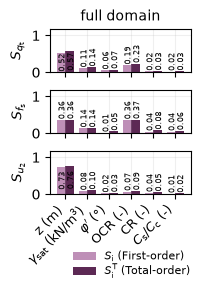

In [324]:
import matplotlib.colors as mcolors
# Plot Sobol first-order indices
n_out = len(outputs)
fig, axes = plt.subplots(
    n_out, 1,
    figsize=(4.75*cm, 7*cm),  # reuse cm, just a bit wider
    sharex=True
)
if n_out == 1:
    axes = [axes]

# Number of parameters from Sobol indices
n_params = len(sa_first[outputs[0]])
x_pos = np.arange(n_params)
width = 0.4

# Map var_names -> keys in latex_names
param_key_map = {
    "z [m]": "z",
    "γ [kN/m3]": "unit_weight",
    "φ' [deg]": "friction_angle",
    "OCR": "orc",
    "CR": "cr",
    "cs/cc": "cs_cc",
    # add more mappings here if var_names contains other names
}

# Build x-tick labels by reusing latex_names when possible
input_labels = []
for name in var_names[:n_params]:
    key = param_key_map.get(name)
    if key is not None and key in latex_names:
        input_labels.append(latex_names[key])
    else:
        input_labels.append(name)


out_label = [r'$S_{q_{\mathrm{t}}}$', r'$S_{f_{\mathrm{s}}}$', r'$S_{u_2}$']


def lighten(color, factor=0.5):
    """Blend color towards white."""
    rgba = np.array(mcolors.to_rgba(color))
    rgba[:3] = 1 - (1 - rgba[:3]) * (1 - factor)
    return rgba

def darken(color, factor=0.4):
    """Blend color towards black."""
    rgba = np.array(mcolors.to_rgba(color))
    rgba[:3] = rgba[:3] * (1 - factor)
    return rgba

# Base colors — one per output (reusing your inferno palette)
base_colors = plt.cm.inferno(np.linspace(0.9, 0.34, len(out_label)+1))


if input_sheet == "verysoft":
    target_idx = 0
elif input_sheet == "soft":
    target_idx = 1
elif input_sheet == "medium":
    target_idx = 2
elif input_sheet == "stiff":
    target_idx = 3
else:
    target_idx = 3  # default for full domain

base      = base_colors[target_idx]
col_light = lighten(base, factor=0.45)
col_dark  = darken(base,  factor=0.40)


threshold = 0.5

for idx, out_name in enumerate(outputs):
    ax = axes[idx]
    first_vals = sa_first[out_name]
    total_vals = sa_total[out_name]


    bars1 = ax.bar(x_pos - width/2, first_vals, width,
                   label="$S_\mathrm{i}$ (First-order)",
                   color=col_light, alpha=0.9)
    bars2 = ax.bar(x_pos + width/2, total_vals, width,
                   label=r"$S_\mathrm{i}^{\mathrm{T}}$ (Total-order)",
                   color=col_dark, alpha=0.9)

    ax.set_ylim(0, 1.18)

    for bars, vals, col_out in [
        (bars1, first_vals, col_light),
        (bars2, total_vals, col_dark),
    ]:
        for bar, val in zip(bars, vals):
            xc = bar.get_x() + bar.get_width() / 2 + 0.06
            yc = bar.get_height() / 2

            if val > threshold:
                ax.annotate(f"{val:.2f}",
                            xy=(xc, yc),
                            ha='center', va='center',
                            rotation=90, fontsize=5.5,
                            color='k',
                            annotation_clip=False)
            else:
                ax.annotate(f"{val:.2f}",
                            xy=(xc, bar.get_height() + 0.02),
                            ha='center', va='bottom',
                            rotation=90, fontsize=5.5,
                            color='k',
                            annotation_clip=False)

    ax.set_ylabel(out_label[idx])
    ax.set_xticks(x_pos)
    ax.set_xticklabels(input_labels, rotation=45, ha="right", fontsize=9)
    ax.grid(True, alpha=0.2, lw=0.8)

handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc='upper left',
           bbox_to_anchor=(0.3, 0.13
                           ), frameon=False, labelspacing=0.08, fontsize=8)

if input_sheet == 'verysoft':
    axes[0].set_title("very soft", fontsize=10)
elif input_sheet == 'soft':
    axes[0].set_title("soft", fontsize=10)
elif input_sheet == 'medium':
    axes[0].set_title("medium", fontsize=10)
elif input_sheet == 'stiff':
    axes[0].set_title("stiff", fontsize=10)
else:
    axes[0].set_title("full domain", fontsize=10)

plt.subplots_adjust(left=0.23, bottom=0.3, right=0.98, top=0.9, hspace=0.4)

# Save all three formats from the same figure
base = PLOTS_DIR / f"sobol_indices_qt_fs_u2_{input_sheet}"

plt.savefig(f"{base}.pdf", dpi=1000)
plt.savefig(f"{base}.tiff", dpi=1000)
plt.savefig(f"{base}.jpg", dpi=1000)


In [325]:
input_labels

['z (m)',
 '$\\gamma_{\\mathrm{sat}}$ (kN/m$^3$)',
 "$\\varphi'~(°)$",
 'OCR (-)',
 '$\\mathrm{CR}$ (-)',
 '$C_{\\mathrm{s}}/C_{\\mathrm{c}}$ (-)']

In [326]:
param_labels_s2 = results['VariableNames']
n_params_s2 = len(param_labels_s2)
outputs = output_var_names
n_out = len(outputs)

# Initialize the dictionary of matrices
sa_second = {out_name: np.zeros((n_params_s2, n_params_s2)) for out_name in outputs}

# 1. Get the pair mapping and the values
# VarIdx[1] contains the pairs like [1, 2], [1, 3], etc.
# AllOrders[1] contains the values for those pairs
if 'AllOrders' in results and len(results['AllOrders']) > 1:
    pairs = results['VarIdx'][1]      # The list of variable pairs
    s2_values = results['AllOrders'][1]  # The interaction values
    
    for pair_idx, pair in enumerate(pairs):
        # Convert 1-based UQ[py]Lab indices to 0-based Python indices
        v1, v2 = pair[0] - 1, pair[1] - 1
        
        # Extract values for each output
        for out_idx in range(n_out):
            out_name = outputs[out_idx]
            val = s2_values[pair_idx][out_idx]
            
            # Fill the matrix symmetrically
            sa_second[out_name][v1, v2] = val
            sa_second[out_name][v2, v1] = val

print("Second-order matrices successfully reconstructed from AllOrders.")

Second-order matrices successfully reconstructed from AllOrders.


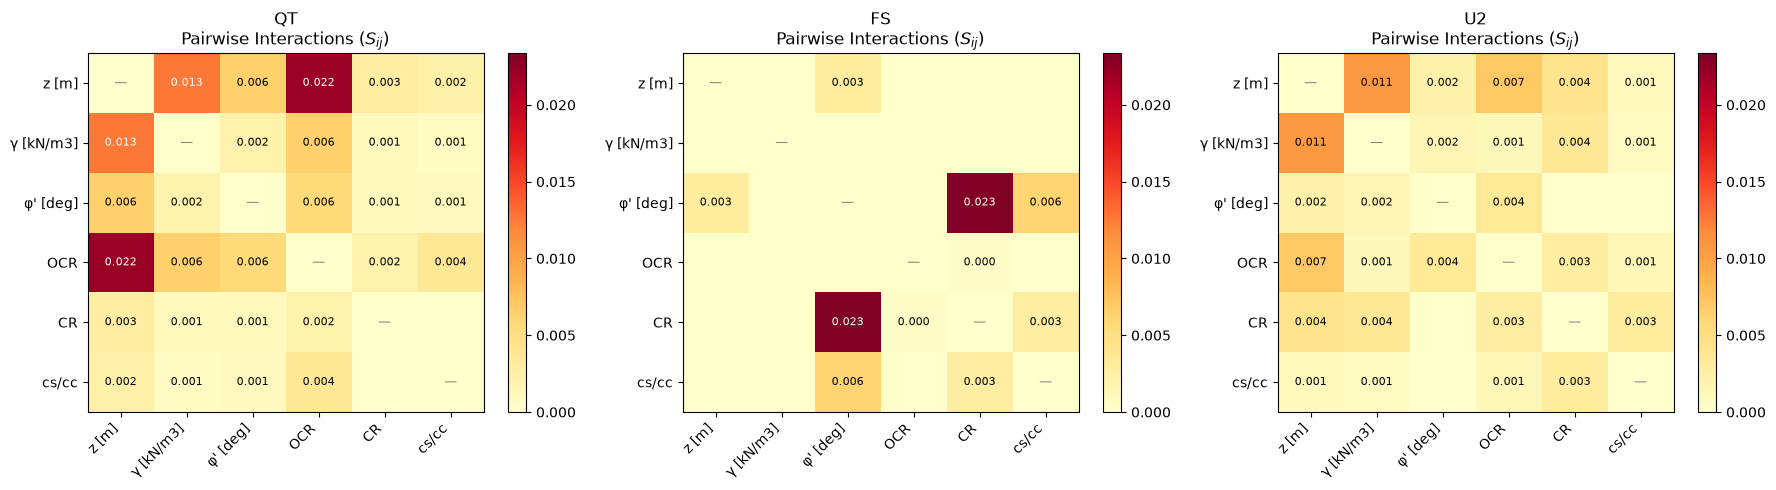

In [327]:
# Plot second-order Sobol indices (interactions) as heatmaps
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

# Find global max for consistent color scale
global_max = max([np.max(sa_second[out_name]) for out_name in outputs])
if global_max == 0: global_max = 1.0 # Avoid division by zero

for idx, out_name in enumerate(outputs):
    ax = axes[idx]
    s2_matrix = sa_second[out_name]
    
    im = ax.imshow(s2_matrix, cmap='YlOrRd', aspect='auto', vmin=0, vmax=global_max)
    
    ax.set_xticks(np.arange(n_params_s2))
    ax.set_yticks(np.arange(n_params_s2))
    ax.set_xticklabels(param_labels_s2, rotation=45, ha='right')
    ax.set_yticklabels(param_labels_s2)
    
    for i in range(n_params_s2):
        for j in range(n_params_s2):
            if i != j:
                val = s2_matrix[i, j]
                text_color = 'white' if val > global_max * 0.5 else 'black'
                if val > 0.0001: # Only show non-negligible interactions
                    ax.text(j, i, f'{val:.3f}', ha="center", va="center", 
                            color=text_color, fontsize=8)
            else:
                ax.text(j, i, '—', ha="center", va="center", color="gray", fontsize=9)
    
    ax.set_title(f"{out_name.upper()}\nPairwise Interactions ($S_{{ij}}$)")
    cbar = plt.colorbar(im, ax=ax)

plt.tight_layout()
plt.show()

In [328]:
# Generate 1000 samples per soil consistency, run forward PCE, save one file for inverse model
# Table 1: Soil parameters based on consistency (z, γ, φ', OCR, CR, cs/cc)


N_SAMPLES_PER_CONSISTENCY = 400

consistency_ranges = {
    "very soft": {
        "z": (5.0, 20.0),
        "unit_weight": (14.5, 16.0),
        "friction_angle": (15.0, 25.0),
        "ocr": (1.0, 1.5),
        "cr": (0.40, 0.25),
        "cs_cc": (0.200, 0.100),
    },
    "soft": {
        "z": (5.0, 20.0),
        "unit_weight": (15.0, 16.5),
        "friction_angle": (18.0, 28.0),
        "ocr": (1.0, 2.0),
        "cr": (0.30, 0.20),
        "cs_cc": (0.200, 0.125),
    },
    "medium (firm)": {
        "z": (5.0, 20.0),
        "unit_weight": (16.5, 18.0),
        "friction_angle": (20.0, 30.0),
        "ocr": (1.5, 3.0),
        "cr": (0.25, 0.15),
        "cs_cc": (0.250, 0.143),
    },
    "stiff": {
        "z": (5.0, 20.0),
        "unit_weight": (17.0, 19.0),
        "friction_angle": (25.0, 35.0),
        "ocr": (2.0, 4.0),
        "cr": (0.15, 0.07),
        "cs_cc": (0.333, 0.167),
    },
}

# Order of inputs for PCE: z, γ, φ', OCR, CR, cs/cc (same as var_names)
var_order = ["z [m]", "γ [kN/m3]", "φ' [deg]", "OCR", "CR", "cs/cc"]
key_map = {"z [m]": "z", "γ [kN/m3]": "unit_weight", "φ' [deg]": "friction_angle", "OCR": "ocr", "CR": "cr", "cs/cc": "cs_cc"}

samples_list = []
consistency_labels_list = []

for consistency_name, ranges in consistency_ranges.items():
    marginals_consistency = []
    for vname in var_order:
        key = key_map[vname]
        lo, hi = ranges[key]
        lo, hi = min(lo, hi), max(lo, hi)
        marginals_consistency.append({"Name": vname, "Type": "Uniform", "Parameters": [lo, hi]})
    my_input_consistency = uq.createInput({"Marginals": marginals_consistency})
    X_c = np.array(uq.getSample(my_input_consistency, N_SAMPLES_PER_CONSISTENCY, "Sobol"))
    samples_list.append(X_c)
    consistency_labels_list.append(np.full(N_SAMPLES_PER_CONSISTENCY, consistency_name, dtype=object))

X_all = np.vstack(samples_list)  # (4000, 6): z, gamma, phi, ocr, cr, cs_cc
consistency_labels = np.concatenate(consistency_labels_list)

# Forward PCE: input (z, gamma, phi, ocr, cr, cs_cc) -> output (qt, fs, u2)
Y_pred = np.array(uq.evalModel(final_pce, X_all.tolist()))  # (4000, 3): qt, fs, u2

# Build table: inputs gamma, phi, ocr, cr, cs_cc; then outputs depth, qt, fs, rf (u2)
z_col = X_all[:, 0]
gamma_col = X_all[:, 1]
phi_col = X_all[:, 2]
ocr_col = X_all[:, 3]
cr_col = X_all[:, 4]
cs_cc_col = X_all[:, 5]
qt_col = Y_pred[:, 0]
fs_col = np.exp(Y_pred[:, 1])
u2_col = Y_pred[:, 2]

df_inverse = pd.DataFrame({
    "gamma": gamma_col,
    "phi": phi_col,
    "ocr": ocr_col,
    "cr": cr_col,
    "cs_cc": cs_cc_col,
    "depth": z_col,
    "qt": qt_col,
    "fs": fs_col,
    "u2": u2_col,
})
df_inverse["consistency"] = consistency_labels

out_path = DATA_DIR / "02_database" / "inverse_training_consistency_1600.csv"
out_path.parent.mkdir(parents=True, exist_ok=True)
df_inverse.to_csv(out_path, index=False)
print(f"Saved {len(df_inverse)} rows to {out_path}")
print("Columns:", list(df_inverse.columns))

Saved 1600 rows to c:\Users\hari1996\Documents\GitHub\cpt-pce-surrogate\data\02_database\inverse_training_consistency_1600.csv
Columns: ['gamma', 'phi', 'ocr', 'cr', 'cs_cc', 'depth', 'qt', 'fs', 'u2', 'consistency']


In [329]:
# File + sheet
DATA_SUBDIR = "02_database"
DATA_FILE_NAME = "GPFEM_database_20260624.xlsx"
DATA_SHEET_NAME = "Testdata"

# Load summary sheet
df_summary = pd.read_excel(
    DATA_DIR / DATA_SUBDIR / DATA_FILE_NAME,
    sheet_name=DATA_SHEET_NAME,
    skiprows=1,
)

print(df_summary.columns)  # run once, then adjust names below

Index(['z [m]', 'γ [kN/m3]', 'φ' [deg]', 'OCR', 'Rint', 'CR', 'cs/cc', 'ʋᵤᵣ',
       'Unnamed: 8', 'Unnamed: 9', 'Batch', 'Series_Name', 'Gamma',
       'Gamma_\nWater', 'Kappa_\nStar', 'Lambda_\nStar', 'CASM_\nN',
       'CASM_\nR', 'CASM_\nM', 'Shear_\nModulus', 'Poisson_\nRatio', 'M_\nCSL',
       'Friction_\nAngle', 'Precon_\nPressure_P0', 'Permeability',
       'Initial_\nPorosity', 'Initial_\nSigma_V_Eff', 'Initial_\nSigma_H_Eff',
       'Initial_Water\n_Pressure', 'Contact_\nFriction_Angle', 'Unnamed: 30',
       'qt_kPa', 'fs_kPa', 'u2_kPa', 'Qt_normalized', 'fs_normalized',
       'U_normalized', 'remark'],
      dtype='str')


In [330]:
# Adjust these names to match the printed columns exactly
col_depth = "z [m]"           # depth
col_gamma = "γ [kN/m3]"       # unit weight
col_phi   = "φ' [deg]"  # phi'
col_ocr   = "OCR"
col_cr    = "CR"
col_cscc  = "cs/cc"
col_consistency = "Series_Name"  # soil consistency category

# Build input matrix in the SAME order as the PCE expects: (z, gamma, phi, ocr, cr, cs_cc)
X_summary = np.column_stack([
    df_summary[col_depth].values.astype(float),
    df_summary[col_gamma].values.astype(float),
    df_summary[col_phi].values.astype(float),
    df_summary[col_ocr].values.astype(float),
    df_summary[col_cr].values.astype(float),
    df_summary[col_cscc].values.astype(float),
])

In [331]:
soil_consistency = df_summary[col_consistency].values
depth_values = df_summary[col_depth].values

print("X_summary shape:", X_summary.shape)

# True values from database (already loaded via prepare_datasets)
qt_true = df_summary["qt_kPa"].to_numpy(float)  # change column names if different
fs_true = df_summary["fs_kPa"].to_numpy(float)
u2_true = df_summary["u2_kPa"].to_numpy(float)


# Evaluate PCE forward model on the parameters from Summary_filtered
Y_pred_summary = np.array(uq.evalModel(final_pce, X_summary.tolist()))  # (N, 3): qt, fs, u2

qt_pred = Y_pred_summary[:, 0]
fs_log_pred = Y_pred_summary[:, 1]
u2_pred = Y_pred_summary[:, 2]

fs_pred = np.exp(fs_log_pred)

X_summary shape: (800, 6)


In [332]:
# soil_consistency is your existing array: ['verysoft1', ..., 'stiff450', ...]
soil_consistency = np.asarray(soil_consistency, dtype=object)

def base_consistency(label: str) -> str:
    # keep only the leading letters, drop trailing digits
    m = re.match(r"([a-zA-Z]+)", str(label))
    return m.group(1).lower() if m else str(label).lower()

soil_consistency_group = np.array([base_consistency(s) for s in soil_consistency])

print("Unique groups:", pd.unique(soil_consistency_group))

Unique groups: ['stiff' 'medium' 'soft' 'verysoft']


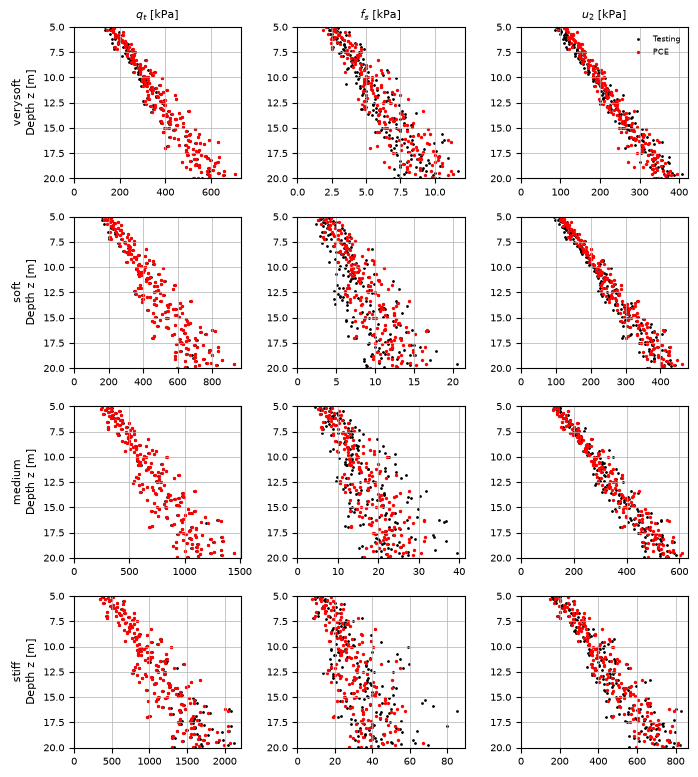

In [333]:
# choose the 4 main groups explicitly
target_groups = ["verysoft", "soft", "medium", "stiff"]  # adjust to what you saw above
unique_consistencies = [g for g in target_groups if g in soil_consistency_group]


true_series = [qt_true, fs_true, u2_true]
pred_series = [qt_pred, fs_pred, u2_pred]

fig, axes = plt.subplots(
    nrows=len(unique_consistencies), ncols=3,
    figsize=(3 * 6 * cm, len(unique_consistencies) * 5 * cm),
    sharex=False, sharey=False
)
if len(unique_consistencies) == 1:
    axes = np.array([axes])  # ensure 2D

for i, cons in enumerate(unique_consistencies):
    mask = soil_consistency_group == cons   # many rows per group now

    for j in range(3):
        ax = axes[i, j]
        y_depth = depth_values[mask]
        x_true = true_series[j][mask]
        x_pred = pred_series[j][mask]

        sort_idx = np.argsort(y_depth)
        y_depth_sorted = y_depth[sort_idx]
        x_true_sorted = x_true[sort_idx]
        x_pred_sorted = x_pred[sort_idx]

        ax.scatter(x_true_sorted, y_depth_sorted, label="Testing", s = 1, c = 'k')
        ax.scatter(x_pred_sorted, y_depth_sorted, label="PCE", s = 2, c = 'r')
        ax.grid(lw = 0.5)
        ax.invert_yaxis()
        ax.set_xlim(xmin = 0)
        ax.set_ylim(ymax = 5, ymin = 20)
        
        if i == 0:
            ax.set_title(["$q_t$ [kPa]", "$f_s$ [kPa]", "$u_2$ [kPa]"][j], fontsize=8)
        if j == 0:
            ax.set_ylabel(f"{cons}\nDepth z [m]", fontsize=8)
        ax.tick_params(labelsize=7)
        if i == 0 and j == 2:
            ax.legend(fontsize=6, loc="upper right", frameon=False)

plt.tight_layout()
plt.show()

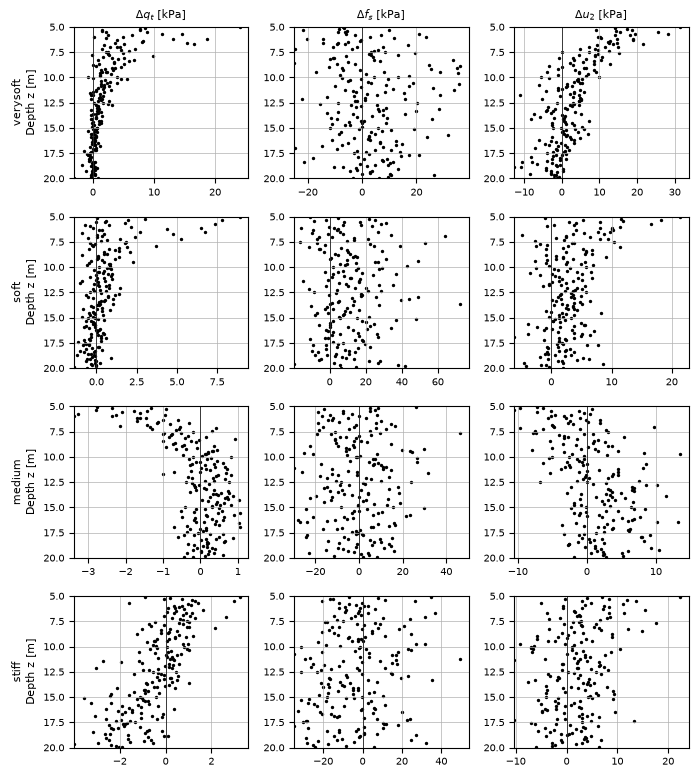

In [334]:
# --- Residual plots: PCE error vs depth per consistency and variable ---

# Choose whether to use absolute or relative error
# Here: residual = PCE - Testing
residual_series = [(qt_pred - qt_true)/qt_true*100,
                   (fs_pred - fs_true)/fs_true*100,
                   (u2_pred - u2_true)/u2_true*100]

fig_res, axes_res = plt.subplots(
    nrows=len(unique_consistencies), ncols=3,
    figsize=(3 * 6 * cm, len(unique_consistencies) * 5 * cm),
    sharex=False, sharey=False
)
if len(unique_consistencies) == 1:
    axes_res = np.array([axes_res])

for i, cons in enumerate(unique_consistencies):
    mask = soil_consistency_group == cons

    for j in range(3):
        ax = axes_res[i, j]
        y_depth = depth_values[mask]
        err = residual_series[j][mask]

        sort_idx = np.argsort(y_depth)
        y_depth_sorted = y_depth[sort_idx]
        err_sorted = err[sort_idx]

        ax.scatter(err_sorted, y_depth_sorted, s=2, c="k")
        ax.axvline(0.0, color="k", lw=0.5)  # zero-error line
        ax.grid(lw=0.5)
        ax.invert_yaxis()
        ax.set_xlim(left=min(err_sorted.min(), -1.0))  # optional: tighten later
        ax.set_ylim(ymax=5, ymin=20)

        if i == 0:
            ax.set_title(
                [r"$\Delta q_t$ [kPa]", r"$\Delta f_s$ [kPa]", r"$\Delta u_2$ [kPa]"][j],
                fontsize=8,
            )
        if j == 0:
            ax.set_ylabel(f"{cons}\nDepth z [m]", fontsize=8)
        ax.tick_params(labelsize=7)

plt.tight_layout()
plt.show()

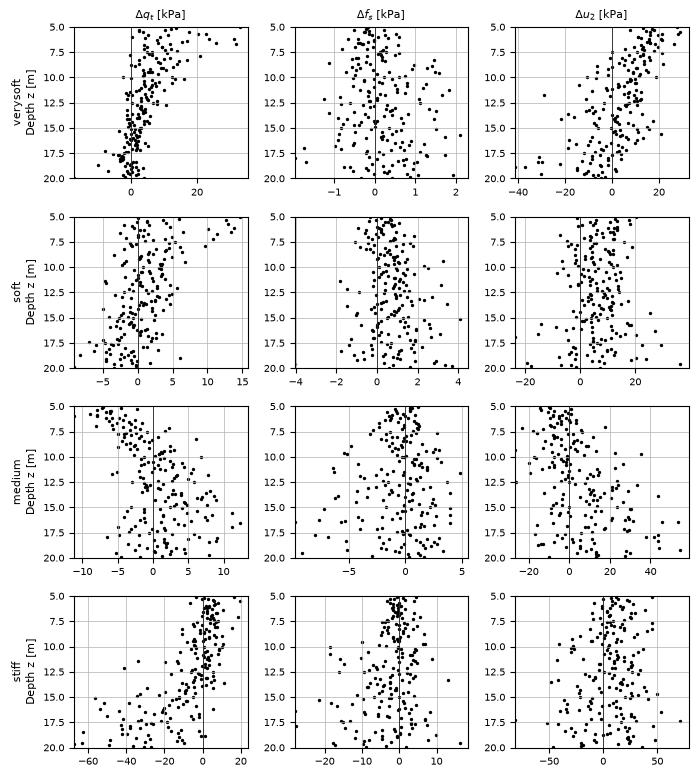

In [335]:
# --- Residual plots: PCE error vs depth per consistency and variable ---

# Choose whether to use absolute or relative error
# Here: residual = PCE - Testing
residual_series = [(qt_pred - qt_true),
                   (fs_pred - fs_true),
                   (u2_pred - u2_true)]

fig_res, axes_res = plt.subplots(
    nrows=len(unique_consistencies), ncols=3,
    figsize=(3 * 6 * cm, len(unique_consistencies) * 5 * cm),
    sharex=False, sharey=False
)
if len(unique_consistencies) == 1:
    axes_res = np.array([axes_res])

for i, cons in enumerate(unique_consistencies):
    mask = soil_consistency_group == cons

    for j in range(3):
        ax = axes_res[i, j]
        y_depth = depth_values[mask]
        err = residual_series[j][mask]

        sort_idx = np.argsort(y_depth)
        y_depth_sorted = y_depth[sort_idx]
        err_sorted = err[sort_idx]

        ax.scatter(err_sorted, y_depth_sorted, s=2, c="k")
        ax.axvline(0.0, color="k", lw=0.5)  # zero-error line
        ax.grid(lw=0.5)
        ax.invert_yaxis()
        ax.set_xlim(left=min(err_sorted.min(), -1.0))  # optional: tighten later
        ax.set_ylim(ymax=5, ymin=20)

        if i == 0:
            ax.set_title(
                [r"$\Delta q_t$ [kPa]", r"$\Delta f_s$ [kPa]", r"$\Delta u_2$ [kPa]"][j],
                fontsize=8,
            )
        if j == 0:
            ax.set_ylabel(f"{cons}\nDepth z [m]", fontsize=8)
        ax.tick_params(labelsize=7)

plt.tight_layout()
plt.show()

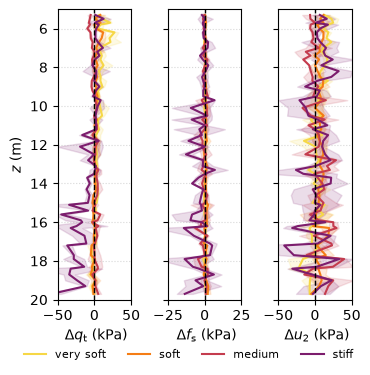

In [336]:
# 1. Compute Absolute Error (Residual = Predicted - True)
# Units are now back to [kPa]
residual_series = [
    (qt_pred - qt_true),
    (fs_pred - fs_true),
    (u2_pred - u2_true)
]


# Define colors for the different consistencies
colors = plt.cm.inferno(np.linspace(0.9, 0.34, len(unique_consistencies)))

# Create 1 row, 3 columns
# Using your requested size: 3 * 6cm width, 10cm height
fig, axes = plt.subplots(1, 3, figsize=(3* 3 * cm, 9 * cm), sharey=True)
titles = [r"$\Delta q_t$ [kPa]", r"$\Delta f_s$ [kPa]", r"$\Delta u_2$ [kPa]"]

for j in range(3):
    ax = axes[j]
    
    # Track min/max for dynamic x-limits (optional)
    all_means = []

    for i, cons in enumerate(unique_consistencies):
        mask = (soil_consistency_group == cons)
        
        y_depth = depth_values[mask]
        err = residual_series[j][mask]
        
        # Create temp dataframe for statistics
        df_temp = pd.DataFrame({'depth': y_depth, 'error': err})
        
        # Binning by depth (0.1m resolution)
        stats = df_temp.groupby(df_temp['depth'].round(1))['error'].agg(['mean', 'std']).dropna()
        
        # Plot Standardabweichung (Standard Deviation)
        ax.fill_betweenx(stats.index, 
                         stats['mean'] - stats['std'], 
                         stats['mean'] + stats['std'], 
                         color=colors[i], alpha=0.15)
        
        # Plot Mean Error
        ax.plot(stats['mean'], stats.index, color=colors[i], lw=1.5, label=cons)
        all_means.extend(stats['mean'].values)

    # Styling
    ax.axvline(0.0, color="k", lw=1, ls="--")  # Zero error line
    # ax.set_title(titles[j])
    ax.grid(True, which='both', linestyle=':', alpha=0.5)
    
    
    # Set y-axis limits (Depth)
    ax.set_xlim(-50, 50)
    ax.set_ylim(5, 20)
    
    ax.invert_yaxis()

    # X-axis handling: Absolute error ranges usually differ greatly between qt and fs
    # We can let them auto-scale or set specific bounds
    
    
    if j == 0:
        ax.set_ylabel("$z$ (m)")
        ax.set_xlabel(" $\Delta q_t$ (kPa)")
        ax.set_xlabel(r" $\Delta q_{\mathrm{t}}$ (kPa)")
        # ax.legend(loc="lower left", frameon=True)
    elif j==1: 
        ax.set_xlabel(" $\Delta f_s$ (kPa)")
        ax.set_xlabel(r" $\Delta f_{\mathrm{s}}$ (kPa)")    
        ax.set_xlim(-25, 25)
    elif j==2:
        ax.set_xlabel(" $\Delta u_2$ (kPa)")
        ax.set_xlabel(r" $\Delta u_2$ (kPa)")
        ax.set_xlim(-50, 50)

# --- Global Legend Configuration ---
# We grab the handles and labels from the first axes
handles, labels = axes[0].get_legend_handles_labels()
labels[0] = "very soft"

# bbox_to_anchor places it. (0.5, -0.05) centers it below the plots.
# ncol=4 makes it 1 row with 4 columns.
fig.legend(handles, labels, loc='lower center', 
           bbox_to_anchor=(0.5, -0.02), ncol=4, 
           frameon=False, labelspacing=0.01, fontsize=8)

# Adjusting rect to make room for the legend at the bottom
plt.subplots_adjust(wspace = 0.5, hspace = 0.2, bottom=0.18, right = 0.96, left = 0.13, top = 1) 

# Save all three formats from the same figure
base = PLOTS_DIR / f"pce_residuals_by_consistency_qt_fs_u2"

plt.savefig(f"{base}.pdf", dpi=1000)
plt.savefig(f"{base}.tiff", dpi=1000)
plt.savefig(f"{base}.jpg", dpi=1000)


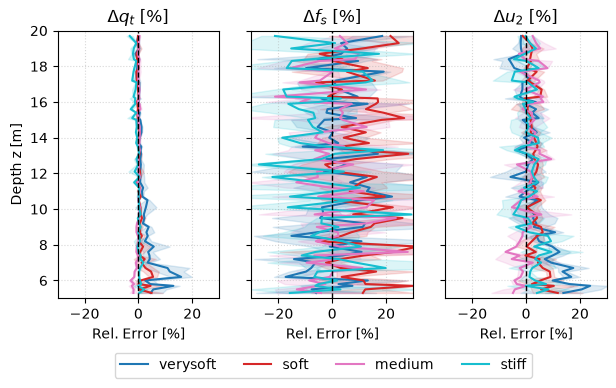

In [337]:
# 1. Compute Relative Error (Difference in Percentage)
residual_series = [(qt_pred - qt_true)/qt_true*100,
                   (fs_pred - fs_true)/fs_true*100,
                   (u2_pred - u2_true)/u2_true*100]

# Define colors for the different consistencies
colors = plt.cm.tab10(np.linspace(0, 1, len(unique_consistencies)))

# Create 1 row, 3 columns
fig, axes = plt.subplots(1, 3, figsize=(3 * 6 * cm, 10 * cm), sharey=True)

# Update titles to show [%] instead of [kPa]
titles = [r"$\Delta q_t$ [%]", r"$\Delta f_s$ [%]", r"$\Delta u_2$ [%]"]

for j in range(3):
    ax = axes[j]
    all_means = []

    for i, cons in enumerate(unique_consistencies):
        mask = (soil_consistency_group == cons)
        
        y_depth = depth_values[mask]
        err = residual_series[j][mask]
        
        # Create temp dataframe for statistics
        df_temp = pd.DataFrame({'depth': y_depth, 'error': err})
        
        # Binning by depth
        stats = df_temp.groupby(df_temp['depth'].round(1))['error'].agg(['mean', 'std']).dropna()
        
        # Plot Standardabweichung (Standard Deviation)
        ax.fill_betweenx(stats.index, 
                         stats['mean'] - stats['std'], 
                         stats['mean'] + stats['std'], 
                         color=colors[i], alpha=0.15)
        
        # Plot Mean Error
        ax.plot(stats['mean'], stats.index, color=colors[i], lw=1.5, label=cons)
        all_means.extend(stats['mean'].values)

    # Styling
    ax.axvline(0.0, color="k", lw=1, ls="--")
    ax.set_title(titles[j])
    ax.grid(True, which='both', linestyle=':', alpha=0.5)
    ax.invert_yaxis()
    
    # Set y-axis limits (Depth)
    ax.set_ylim(5, 20)
    
    # Update x-label to reflect percentage
    ax.set_xlabel("Rel. Error [%]")
    
    # Set X-limits for percentages (standardizing to +/- 50%)
    ax.set_xlim(-30, 30) 
    
    if j == 0:
        ax.set_ylabel("Depth z [m]")
        ax.set_xlim(-30, 30)

    if j == 2:
        ax.set_xlim(-30, 30)

# --- Global Legend Configuration ---
handles, labels = axes[0].get_legend_handles_labels()

# Placed below the plots in 1 row, 4 columns
fig.legend(handles, labels, loc='lower center', 
           bbox_to_anchor=(0.5, -0.02), ncol=4, 
           frameon=True)

# Adjust spacing to accommodate the legend
plt.subplots_adjust(wspace=0.2, hspace=0.2, bottom=0.2) 


In [338]:
x_names = ["z", "gamma", "phi", "ocr", "cr", "cs_cc"]
y_names = ["qt", "fs", "u2"]

# Use first output's indices as the basis (same for all if LARS used same ED)
indices = np.array(pce_int[0]["Basis"]["Indices"])
df_out  = pd.DataFrame(indices, columns=[f"alpha_{n}" for n in x_names])

for j, y_name in enumerate(y_names):
    df_out[f"c_{y_name}"] = np.array(pce_int[j]["Coefficients"]).flatten()

# Save bounds — needed for correct standardisation in the web app
lo = ed.min(axis=0)
hi = ed.max(axis=0)
bounds_df = pd.DataFrame({"variable": x_names, "lo": lo, "hi": hi})

out_dir = Path("pce_exports")
out_dir.mkdir(exist_ok=True)
df_out.to_csv(out_dir / "forward_pce_terms.csv", index=False)
bounds_df.to_csv(out_dir / "forward_bounds.csv", index=False)

print("Saved forward_pce_terms.csv:", df_out.shape)
print("Saved forward_bounds.csv")
print(df_out.head())

Saved forward_pce_terms.csv: (84, 9)
Saved forward_bounds.csv
   alpha_z  alpha_gamma  alpha_phi  alpha_ocr  alpha_cr  alpha_cs_cc  \
0        0            0          0          0         0            0   
1        0            0          0          0         0            1   
2        0            0          0          0         1            0   
3        0            0          0          1         0            0   
4        0            0          1          0         0            0   

         c_qt      c_fs        c_u2  
0  724.961543  2.650449  334.747612  
1  -45.880104 -0.118919  -12.595509  
2  -51.606270 -0.118266  -24.187187  
3  148.190534  0.341564   35.096809  
4   79.672845  0.062655   19.744561  


In [339]:
# --- 1) Test-case definition -------------------------------------------------
test_case_params = {
    "Lambda_Star": 0.0774,   # λ*
    "Kappa_Star":  0.0139,   # κ*
    "Friction_Angle": 25.0,  # φ' [deg]
    "OCR": 1.0,
    "K0": 0.58,
    "Initial_Sigma_V_Eff": {8: -33,  10: -42,  12: -53},
    "Initial_Sigma_H_Eff": {8: -19.1,10: -24.3, 12: -30.6},
    "Initial_Water_Pressure": {8: -85, 10: -105, 12: -125},
    "unit_weight": {8: 14.5, 10: 15.0, 12: 15.5},
    # "cpt_measurements": {
    #     8:  {"qt": 205, "fs": 1.4, "u2": 148},
    #     10: {"qt": 263, "fs": 2.3, "u2": 187},
    #     12: {"qt": 319, "fs": 3.5, "u2": 227},
    # },
    # Actual/measured outputs for comparison (optional; leave or update from measurements)
    "cpt_measurements": {
        8: {"qt": 213, "fs": 2.7, "u2": 144},    # qt, fs, u2 in kPa
        10: {"qt": 273, "fs": 3.9, "u2": 186},
        12: {"qt": 331, "fs": 6.1, "u2": 220},
    }
}

depths = sorted(test_case_params["unit_weight"].keys())

# --- 2) Print global parameter ranges vs test values -------------------------
print("Test Case Parameters")
print("=" * 80)
print("\nTraining data parameter ranges (PCE model bounds):")
hdr = f"{'Parameter':<20} {'Min (Training)':<18} {'Max (Training)':<18} {'Test Value':<15} {'In Range?':<12}"
print(hdr)
print("-" * len(hdr))

param_mapping = {
    "lambda":          "Lambda_Star",
    "kappa":           "Kappa_Star",
    "friction_angle":  "Friction_Angle",
    "ocr":             "OCR",
}

for key_pce, key_test in param_mapping.items():
    if key_pce in param_ranges:
        p_min, p_max = param_ranges[key_pce]
        val = float(test_case_params[key_test])
        in_range = "✓ Yes" if p_min <= val <= p_max else "✗ No (EXTRAPOLATION)"
        print(f"{key_test:<20} {p_min:<18.6f} {p_max:<18.6f} {val:<15.6f} {in_range:<12}")

# depth- and stress-related ranges
z_min, z_max              = param_ranges.get("z", (0, 0))
gamma_min, gamma_max      = param_ranges.get("unit_weight", (0, 0))
sig_v_min, sig_v_max      = param_ranges.get("initial_sigma_v_eff", (0, 0))
sig_h_min, sig_h_max      = param_ranges.get("initial_sigma_h_eff", (0, 0))
u_min, u_max              = param_ranges.get("initial_water_pressure", (0, 0))

print("\nTraining ranges:")
print(f"  Depth (z):                [{z_min:.3f}, {z_max:.3f}] m")
print(f"  Unit Weight (γ):          [{gamma_min:.3f}, {gamma_max:.3f}] kN/m³")
print(f"  Initial_Sigma_V_Eff:      [{sig_v_min:.3f}, {sig_v_max:.3f}] kPa")
print(f"  Initial_Sigma_H_Eff:      [{sig_h_min:.3f}, {sig_h_max:.3f}] kPa")
print(f"  Initial_Water_Pressure:   [{u_min:.3f}, {u_max:.3f}] kPa")

# --- 3) Build depth-dependent inputs and show in-range status ----------------
print("\nDepth-dependent parameters (σ'_v, σ'_h, u0, γ):")
# Option 2: no f-string at all (constants only)
print("{:<10} {:<12} {:<12} {:<10} {:<12} {:<12}".format(
    "Depth [m]", "σ'_v [kPa]", "σ'_h [kPa]", "u0 [kPa]", "γ [kN/m³]", "γ in range?"
))
print("-" * 75)

test_inputs = {}
for z in depths:
    gamma = test_case_params["unit_weight"][z]
    sig_v = test_case_params["Initial_Sigma_V_Eff"][z]
    sig_h = test_case_params["Initial_Sigma_H_Eff"][z]
    u0    = test_case_params["Initial_Water_Pressure"][z]

    gamma_in_range = "✓ Yes" if gamma_min <= gamma <= gamma_max else "✗ No (EXTRAPOLATION)"
    print(f"{z:<10} {sig_v:<12.1f} {sig_h:<12.1f} {u0:<10.1f} {gamma:<12.3f} {gamma_in_range:<12}")

    # Cam–Clay → PCE mapping:
    lam_star = float(test_case_params["Lambda_Star"])
    kap_star = float(test_case_params["Kappa_Star"])

    CR        = 2.303 * lam_star
    cs_over_cc = kap_star / lam_star

    # Values in the order expected by forward PCE (must match var_names exactly)
    val_by_name = {
        "z [m]":        float(z),
        "γ [kN/m3]":    gamma,
        "φ' [deg]":     test_case_params["Friction_Angle"],
        "OCR":          test_case_params["OCR"],
        "CR":           CR,
        "cs/cc":        cs_over_cc,
    }

    input_array = np.array([val_by_name[name] for name in var_names], dtype=float)

    test_inputs[z] = {
        "z":           z,
        "unit_weight": gamma,
        "sigma_v":     sig_v,
        "sigma_h":     sig_h,
        "u0":          u0,
        "input_array": input_array,
        "gamma_in_range": gamma_in_range,
    }

print("\n" + "=" * 60)

Test Case Parameters

Training data parameter ranges (PCE model bounds):
Parameter            Min (Training)     Max (Training)     Test Value      In Range?   
---------------------------------------------------------------------------------------
Friction_Angle       15.005246          34.971546          25.000000       ✓ Yes       
OCR                  1.004419           3.993565           1.000000        ✗ No (EXTRAPOLATION)

Training ranges:
  Depth (z):                [5.049, 19.954] m
  Unit Weight (γ):          [14.516, 18.993] kN/m³
  Initial_Sigma_V_Eff:      [0.000, 0.000] kPa
  Initial_Sigma_H_Eff:      [0.000, 0.000] kPa
  Initial_Water_Pressure:   [0.000, 0.000] kPa

Depth-dependent parameters (σ'_v, σ'_h, u0, γ):
Depth [m]  σ'_v [kPa]   σ'_h [kPa]   u0 [kPa]   γ [kN/m³]    γ in range? 
---------------------------------------------------------------------------
8          -33.0        -19.1        -85.0      14.500       ✗ No (EXTRAPOLATION)
10         -42.0        -24.3 

In [340]:
# --- 4) Run PCE for the test depths -----------------------------------------
print("Making predictions with PCE model...")
print("=" * 60)

test_predictions = {}   # <--- this must exist before plotting

for depth in sorted(test_inputs.keys()):
    x = test_inputs[depth]["input_array"]    # 1D array of 6 inputs
    print(x)
    # Evaluate PCE model; shape (1, 3) for [qt, fs, u2]
    y_pred = np.asarray(uq.evalModel(final_pce, [x.tolist()]))

    test_predictions[depth] = {
        "qt": float(y_pred[0, 0]),
        "fs": float(y_pred[0, 1]),
        "u2": float(y_pred[0, 2]),
    }

print("Predictions done for depths:", sorted(test_predictions.keys()))

Making predictions with PCE model...
[ 8.         14.5        25.          1.          0.1782522   0.17958656]
[10.         15.         25.          1.          0.1782522   0.17958656]
[12.         15.5        25.          1.          0.1782522   0.17958656]
Predictions done for depths: [8, 10, 12]


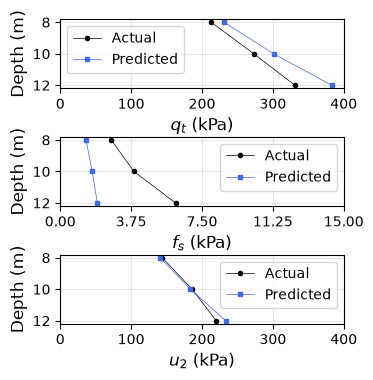

In [341]:
from matplotlib.ticker import LinearLocator

outputs = output_var_names  # e.g. ["qt","fs","u2"]
tc_labels = {
    "depth": "depth (m)",
    "qt": "$q_t$ (kPa)",
    "u2": "$u_2$ (kPa)",
    "fs": "$f_s$ (kPa)",
}
output_labels = [tc_labels.get(o, o) for o in outputs]
depths = sorted(test_inputs.keys())

n_out = len(outputs)
fig, axes = plt.subplots(n_out, 1, figsize=(9*cm, 9*cm))
if n_out == 1:
    axes = [axes]

for idx, (out_name, out_label) in enumerate(zip(outputs, output_labels)):
    ax = axes[idx]

    actual_vals    = [test_case_params["cpt_measurements"][d][out_name] for d in depths]
    predicted_vals = [test_predictions[d][out_name] for d in depths]

    ax.plot(actual_vals,    depths, "o-", label="Actual",
            linewidth=0.5, markersize=3, color="k")
    ax.plot(predicted_vals, depths, "s-", label="Predicted",
            linewidth=0.5, markersize=3, color="royalblue")

    ax.set_ylabel("Depth (m)", fontsize=12)
    ax.set_xlabel(out_label, fontsize=12)
    ax.legend()
    ax.grid(True, alpha=0.3)
    ax.invert_yaxis()
    ax.set_xlim(left=0)
    ax.xaxis.set_major_locator(LinearLocator(5))

    # # add % error annotations at predicted points
    # for val_act, val_pred, z in zip(actual_vals, predicted_vals, depths):
    #     err = val_pred - val_act
    #     err_pct = (err / val_act) * 100 if val_act != 0 else np.nan
    #     ax.annotate(f"{err_pct:+.1f}%",
    #                 xy=(val_pred, z),
    #                 xytext=(5, 5),
    #                 textcoords="offset points",
    #                 fontsize=9,
    #                 bbox=dict(boxstyle="round,pad=0.3",
    #                           facecolor="yellow", alpha=0.5))

# axis ranges per output (qt, fs, u2)
axes[0].set_xlim(right=400)  # qt
axes[1].set_xlim(right=15)   # fs
axes[2].set_xlim(right=400)  # u2

plt.subplots_adjust(left=0.15, bottom=0.13, right=0.95,
                    top=0.99, wspace=0.45, hspace=0.7)
plt.savefig(PLOTS_DIR / "pce_depth_based_test_case_comparison.jpeg", dpi=1000)

In [342]:
test = pd.read_csv(DATA_DIR / "04_test_doc" / "cpt_predictions.csv")
print(test.head())

     z  gamma   phi  ocr   cr  cs_cc   lambda   kappa  qt_kPa  fs_kPa  u2_kPa  \
0  5.5   16.5  25.0  2.0  0.2  0.175  0.08684  0.0152  286.42  6.4461  137.52   
1  6.0   16.5  25.0  2.0  0.2  0.175  0.08684  0.0152  313.01  6.9849  150.01   
2  6.5   16.5  25.0  2.0  0.2  0.175  0.08684  0.0152  339.57  7.5349  162.59   
3  7.0   16.5  25.0  2.0  0.2  0.175  0.08684  0.0152  366.11  8.0933  175.27   
4  7.5   16.5  25.0  2.0  0.2  0.175  0.08684  0.0152  392.62  8.6574  188.03   

    rf_%  
0  2.251  
1  2.232  
2  2.219  
3  2.211  
4  2.205  


In [343]:
x = test.iloc[:, 0:6].values.astype(float)  # assuming first column is depth, rest are inputs
y_pred = np.asarray(uq.evalModel(final_pce, x.tolist()))  # shape (N, 3)

print(y_pred[:5])  # print first 5 predictions

[[286.42441      1.86347368 137.52123802]
 [313.00924724   1.94375279 150.00635749]
 [339.57066812   2.01954729 162.59188783]
 [366.10867263   2.09103944 175.27010684]
 [392.62326077   2.15841152 188.03329231]]


In [344]:
test.head()

,z,gamma,phi,ocr,cr,cs_cc,lambda,kappa,qt_kPa,fs_kPa,u2_kPa,rf_%
0,5.5,16.5,25.0,2.0,0.2,0.175,0.08684,0.0152,286.42,6.4461,137.52,2.251
1,6.0,16.5,25.0,2.0,0.2,0.175,0.08684,0.0152,313.01,6.9849,150.01,2.232
2,6.5,16.5,25.0,2.0,0.2,0.175,0.08684,0.0152,339.57,7.5349,162.59,2.219
3,7.0,16.5,25.0,2.0,0.2,0.175,0.08684,0.0152,366.11,8.0933,175.27,2.211
4,7.5,16.5,25.0,2.0,0.2,0.175,0.08684,0.0152,392.62,8.6574,188.03,2.205


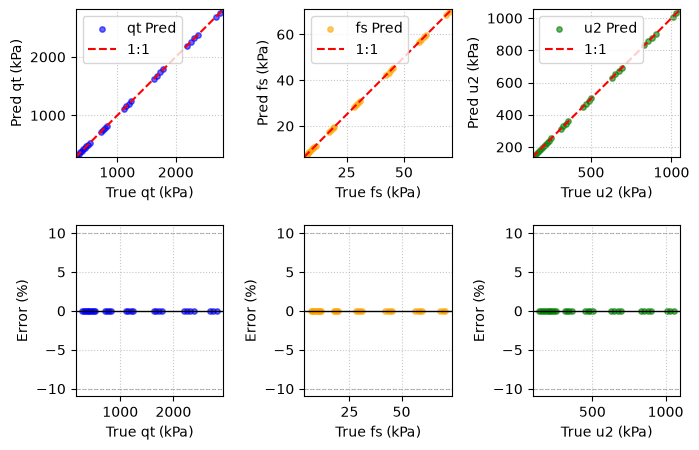

In [345]:
test[["qt_pred", "fs_pred", "u2_pred"]] = y_pred
y_true = test[["qt_kPa", "fs_kPa", "u2_kPa"]].values.astype(float)

test["qt_error_pct"] = (test["qt_pred"] - test["qt_kPa"]) / test["qt_kPa"] * 100
test["fs_error_pct"] = (test["fs_pred"] - test["fs_kPa"]) / test["fs_kPa"] * 100
test["u2_error_pct"] = (test["u2_pred"] - test["u2_kPa"]) / test["u2_kPa"] * 100


# --- 1. (Self-Correction/Update) Ensure fs error is on the physical scale ---
# If test["fs_pred"] is log-space, we calculate the pct error using the exponentiated values
test["fs_error_pct_linear"] = (np.exp(test["fs_pred"]) - test["fs_kPa"]) / test["fs_kPa"] * 100

# Create a 2x3 grid (2 rows, 3 columns)
fig, axes = plt.subplots(2, 3, figsize=(3*6*cm, 12*cm))

# Row 0: Prediction vs True
# Row 1: Residuals vs True

variables = [
    {"name": "qt", "true": "qt_kPa", "pred": "qt_pred", "err": "qt_error_pct", "color": "blue"},
    {"name": "fs", "true": "fs_kPa", "pred": "fs_pred", "err": "fs_error_pct_linear", "color": "orange"},
    {"name": "u2", "true": "u2_kPa", "pred": "u2_pred", "err": "u2_error_pct", "color": "green"}
]

for i, var in enumerate(variables):
    # --- Top Row: Predicted vs True ---
    ax_top = axes[0, i]
    
    # Extract data (handling the exp transformation for fs)
    x_val = test[var["true"]]
    y_val = np.exp(test[var["pred"]]) if var["name"] == "fs" else test[var["pred"]]
    
    ax_top.scatter(x_val, y_val, label=f"{var['name']} Pred", color=var["color"], s=15, alpha=0.6)
    
    # 45-degree line logic
    mn = min(x_val.min(), y_val.min())
    mx = max(x_val.max(), y_val.max())
    ax_top.plot([mn, mx], [mn, mx], color='red', linestyle='--', lw=1.5, label='1:1')
    
    ax_top.set_xlim([mn, mx]), ax_top.set_ylim([mn, mx])
    ax_top.set_aspect('equal')
    ax_top.set_xlabel(f"True {var['name']} (kPa)")
    ax_top.set_ylabel(f"Pred {var['name']} (kPa)")
    ax_top.legend()
    ax_top.grid(True, linestyle=':', alpha=0.7)

    # --- Bottom Row: Residuals ---
    ax_bot = axes[1, i]
    err_val = test[var["err"]]
    
    ax_bot.scatter(x_val, err_val, color=var["color"], s=15, alpha=0.6)
    
    # Add zero-error baseline
    ax_bot.axhline(0, color='black', linestyle='-', lw=1)
    
    # Add +/- 10% or 20% bounds for reference
    ax_bot.axhline(10, color='gray', linestyle='--', lw=0.8, alpha=0.5)
    ax_bot.axhline(-10, color='gray', linestyle='--', lw=0.8, alpha=0.5)
    
    ax_bot.set_xlabel(f"True {var['name']} (kPa)")
    ax_bot.set_ylabel("Error (%)")
    ax_bot.grid(True, linestyle=':', alpha=0.7)
    
    # Optional: limit Y-axis if there are extreme outliers to keep plot readable
    # ax_bot.set_ylim([-50, 50]) 

plt.tight_layout()

In [346]:
# Close UQ[PY]LAB session
mySession.quit()
print("UQ[PY]LAB session closed.")

 uqpylab.sessions :: INFO     :: Session None terminated.
UQ[PY]LAB session closed.
